# 08 · Daily Demand Forecast for Capacity Planning

**Business problem** (from notebook 02): demand peaks break logistics, with the late rate jumping from 3–6% to 12–19%.
Carriers and warehouses need a **28-day volume forecast** to book capacity ahead.

**Approach**
- Daily orders, Jan 2017 – 21 Aug 2018. The data after 21 Aug is truncated by the dataset extraction (shown below).
- **Rolling-origin backtest**: 4 folds × 28 days, always training only on the past.
- Compared against naive baselines, because a model that can't beat "same weekday last week" isn't worth running.
- Judged on daily error **and** on the error of the 28-day total, which is what capacity is booked on.

Code: [`src/ecom/models/forecast.py`](../src/ecom/models/forecast.py)

In [ ]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from ecom import viz

warnings.filterwarnings("ignore", category=UserWarning)
viz.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

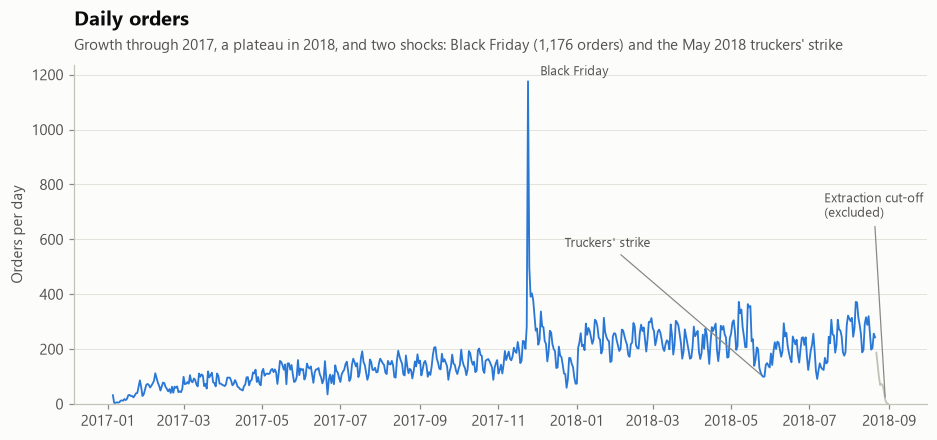

In [ ]:
from ecom.db import query
from ecom.models import forecast

full = query("""SELECT purchase_date AS day, count(*) AS orders FROM marts.fact_orders
                WHERE in_analysis_window GROUP BY 1 ORDER BY 1""").set_index("day")["orders"]
full.index = pd.to_datetime(full.index)
series = forecast.daily_orders()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(series.index, series, color=viz.BLUE, linewidth=1.2)
tail = full[full.index > forecast.LAST_COMPLETE_DAY]
ax.plot(tail.index, tail, color=viz.NEUTRAL, linewidth=1.2)
offsets = {"Black Friday": (8, 4), "Truckers' strike": (-130, 85)}
for day, label in forecast.EVENTS.items():
    point = day if label == "Black Friday" else day + pd.Timedelta(days=5)  # strike trough
    ax.annotate(
        label,
        (point, series[point]),
        xytext=offsets[label],
        textcoords="offset points",
        fontsize=8.5,
        color=viz.INK_2,
        arrowprops=None
        if label == "Black Friday"
        else dict(arrowstyle="-", color=viz.MUTED, lw=0.8),
    )
ax.annotate(
    "Extraction cut-off\n(excluded)",
    (tail.index[-3], tail.iloc[-3]),
    xytext=(-40, 120),
    textcoords="offset points",
    fontsize=8.5,
    color=viz.INK_2,
    arrowprops=dict(arrowstyle="-", color=viz.MUTED, lw=0.8),
)
ax.set_ylabel("Orders per day")
ax.set_ylim(0)
ax.set_title("Daily orders")
viz.subtitle(
    ax,
    "Growth through 2017, a plateau in 2018, and two shocks: Black Friday (1,176 orders) and the May 2018 truckers' strike",
)
viz.save(fig, "daily_orders")
plt.show()

## Backtest: 4 folds × 28 days

In [ ]:
folds, preds = forecast.backtest(series)
summary = forecast.summarise(folds, preds, series)
summary

,mae,mape_pct,mase,total_28d_abs_err_pct,total_28d_worst_err_pct
model,,,,,
Ensemble (ETS + 4-week mean),48.560,24.790,1.440,9.840,17.560
Seasonal mean (last 4 weeks),54.280,27.180,1.600,11.890,28.290
Seasonal naive (last week),55.860,28.880,1.660,14.030,40.820
"ETS (damped trend + weekly, log)",55.260,28.350,1.650,14.510,36.690


In [ ]:
folds.pivot(index="test_start", columns="model", values="mape_pct").round(1)

model,"ETS (damped trend + weekly, log)",Ensemble (ETS + 4-week mean),Seasonal mean (last 4 weeks),Seasonal naive (last week)
test_start,,,,
2018-05-02,36.300,36.700,37.100,35.900
2018-05-30,35.500,17.400,17.500,39.600
2018-06-27,29.900,28.400,27.100,27.800
2018-07-25,11.700,16.700,27.000,12.100


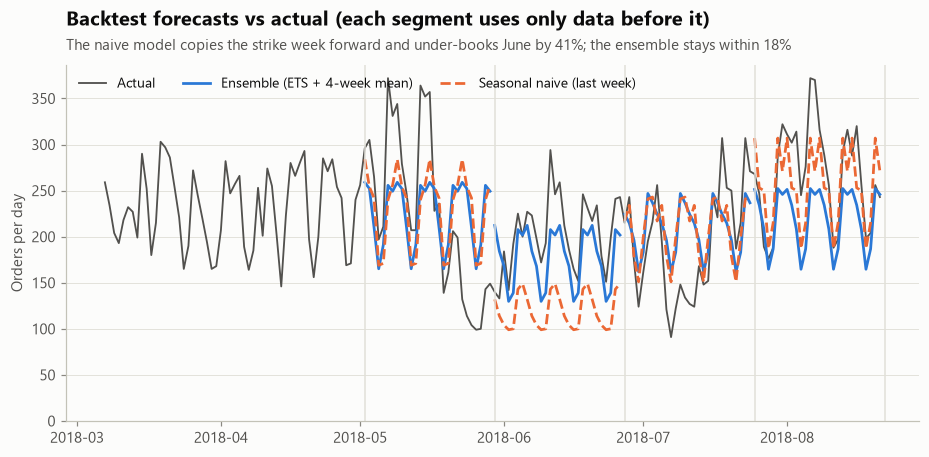

In [ ]:
show = preds[preds["model"].isin(["Ensemble (ETS + 4-week mean)", "Seasonal naive (last week)"])]
start = show["day"].min() - pd.Timedelta(days=56)

fig, ax = plt.subplots(figsize=(10, 4.2))
hist = series[series.index >= start]
ax.plot(hist.index, hist, color=viz.INK_2, linewidth=1.2, label="Actual")
for name, color, style in [
    ("Ensemble (ETS + 4-week mean)", viz.BLUE, "-"),
    ("Seasonal naive (last week)", viz.ORANGE, "--"),
]:
    p = show[show["model"] == name]
    for f in range(forecast.FOLDS):
        chunk = p.iloc[f * forecast.HORIZON : (f + 1) * forecast.HORIZON]
        ax.plot(
            chunk["day"],
            chunk["forecast"],
            color=color,
            linestyle=style,
            linewidth=1.8,
            label=name if f == 0 else None,
        )
for f in range(forecast.FOLDS + 1):
    ax.axvline(
        series.index[-1]
        - pd.Timedelta(days=forecast.HORIZON * (forecast.FOLDS - f))
        + pd.Timedelta(days=1),
        color=viz.GRID,
        linewidth=1,
    )
ax.set_ylim(0)
ax.set_ylabel("Orders per day")
ax.legend(loc="upper left", ncols=3)
ax.set_title("Backtest forecasts vs actual (each segment uses only data before it)")
viz.subtitle(
    ax,
    "The naive model copies the strike week forward and under-books June by 41%; the ensemble stays within 18%",
)
viz.save(fig, "forecast_backtest")
plt.show()

**Why the ensemble wins:** ETS reacts fast, which makes it excellent in calm periods (28-day totals within ~2–7%),
but it extrapolates shocks such as the strike. The 4-week mean is sturdy against shocks but slow to catch rebounds.
Averaging them hedges the two failure modes. The worst 28-day miss falls from **41%** (naive) to **~18%**,
and for capacity booking the worst case matters more than the average.

## Forecast for the next 28 days

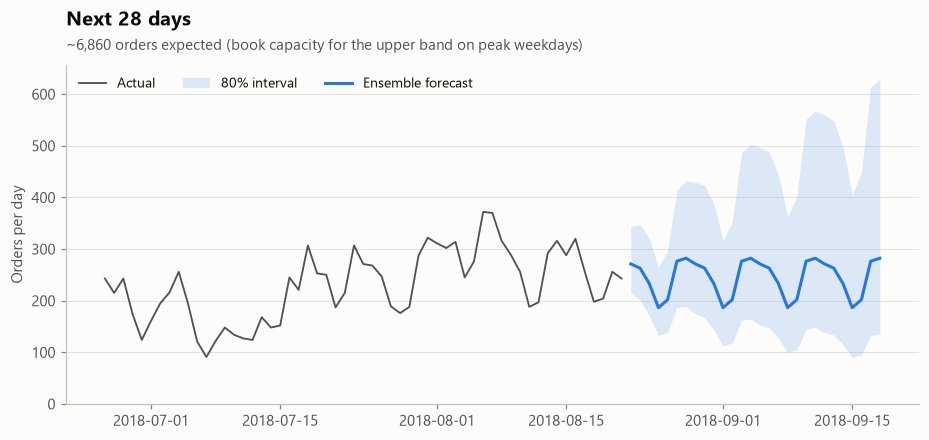

,forecast,low (conservative),high (conservative)
22 Aug – 28 Aug,"1,715.000","1,234.000","2,422.000"
29 Aug – 04 Sep,"1,715.000","1,043.000","2,899.000"
05 Sep – 11 Sep,"1,715.000",926.000,"3,311.000"
12 Sep – 18 Sep,"1,715.000",841.000,"3,700.000"


In [ ]:
fut = forecast.forecast_future(series)
recent = series[series.index >= series.index[-1] - pd.Timedelta(days=56)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(recent.index, recent, color=viz.INK_2, linewidth=1.2, label="Actual")
ax.fill_between(
    fut.index,
    fut["low_80"],
    fut["high_80"],
    color=viz.BLUE,
    alpha=0.15,
    linewidth=0,
    label="80% interval",
)
ax.plot(fut.index, fut["forecast"], color=viz.BLUE, linewidth=2, label="Ensemble forecast")
ax.set_ylim(0)
ax.set_ylabel("Orders per day")
ax.legend(loc="upper left", ncols=3)
ax.set_title("Next 28 days")
viz.subtitle(
    ax,
    f"~{fut['forecast'].sum():,.0f} orders expected (book capacity for the upper band on peak weekdays)",
)
viz.save(fig, "forecast_next_28d")
plt.show()

# Four 7-day planning blocks. Summing daily bounds gives a conservative (wide) band.
weekly = fut.resample("7D", origin=fut.index[0]).sum().round(0)
weekly.index = [f"{d:%d %b} – {d + pd.Timedelta(days=6):%d %b}" for d in weekly.index]
weekly.columns = ["forecast", "low (conservative)", "high (conservative)"]
weekly

## Conclusions

1. The **ensemble beats every baseline**: daily MAE −13% vs naive, and the worst 28-day error falls from 41% to ~18%.
2. Daily e-commerce demand here is **dominated by shocks** (Black Friday, the truckers' strike), which no history-only model can foresee.
   Production use needs an **event calendar** (promotions, holidays, known disruptions) as manual overrides.
3. **Operational use:** publish the weekly totals with the 80% band every Monday, and book carrier capacity at the upper band for peak weeks.
   This connects directly to the late-delivery spikes in notebook 02.